In [126]:
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
import cv2

In [ ]:
#Insert path to dataset
path = ""

metadata = pd.read_json( path + 'Fundus_CIMT_2903_Dataset/data_info.json')
retina_images = glob(path + 'Fundus_CIMT_2903_Dataset/images/*.png')

In [128]:
len(retina_images), metadata.shape

(5806, (8, 2903))

In [129]:
img_L = plt.imread( path + "Fundus_CIMT_2903_Dataset/images/704259001_L.png")
img_R = plt.imread(path + "Fundus_CIMT_2903_Dataset/images/704259001_R.png")
type(img_L), img_R.shape

(numpy.ndarray, (512, 512, 3))

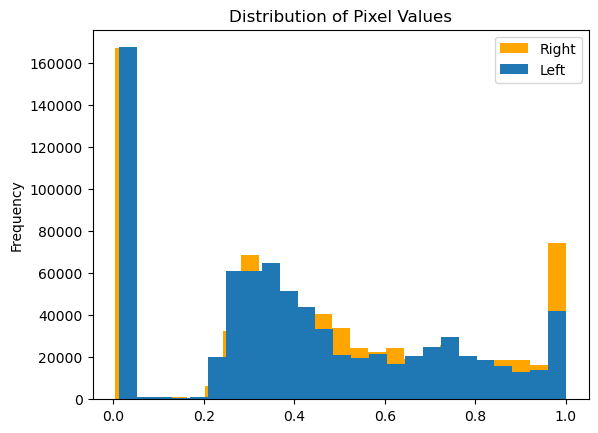

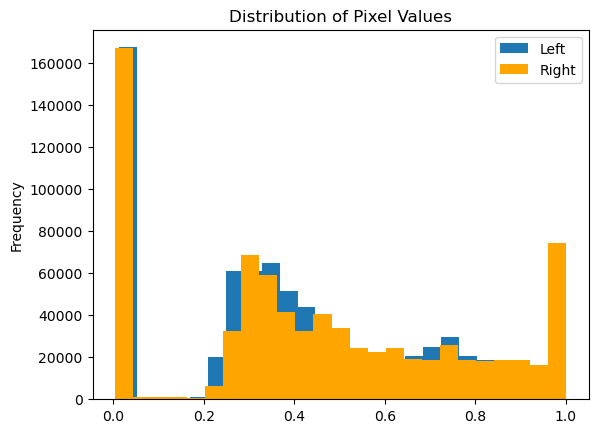

In [130]:
plt.figure()

pd.Series(img_R.flatten()).plot(kind='hist',
                                  bins=25,
                                  label='Right',
                                color='orange')

pd.Series(img_L.flatten()).plot(kind='hist',
                                  bins=25,
                                label='Left',
                                color='#1f77b4')

plt.title("Distribution of Pixel Values")
plt.legend()
plt.show()

plt.figure()

pd.Series(img_L.flatten()).plot(kind='hist',
                                  bins=25,
                                label='Left',
                                color="#1f77b4")
pd.Series(img_R.flatten()).plot(kind='hist',
                                  bins=25,
                                  label='Right',
                                color="orange")

plt.title("Distribution of Pixel Values")
plt.legend()
plt.show()

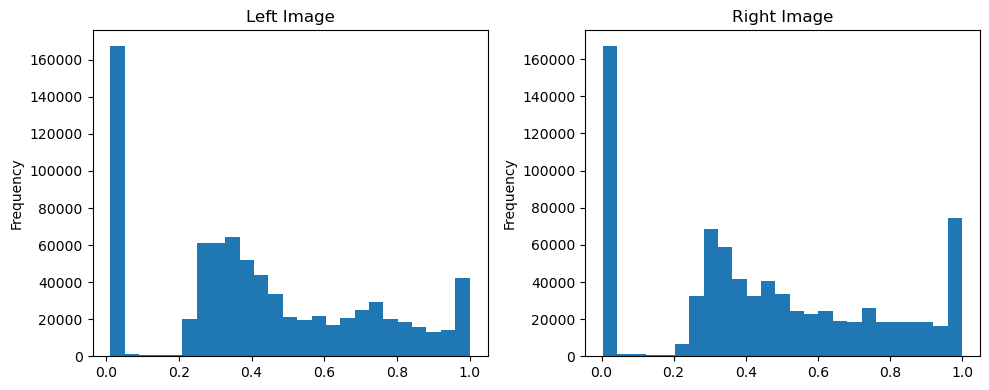

In [131]:
import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

pd.Series(img_L.flatten()).plot(
    kind='hist', bins=25, ax=axes[0], title='Left Image'
)

pd.Series(img_R.flatten()).plot(
    kind='hist', bins=25, ax=axes[1], title='Right Image'
)

plt.tight_layout()
plt.show()


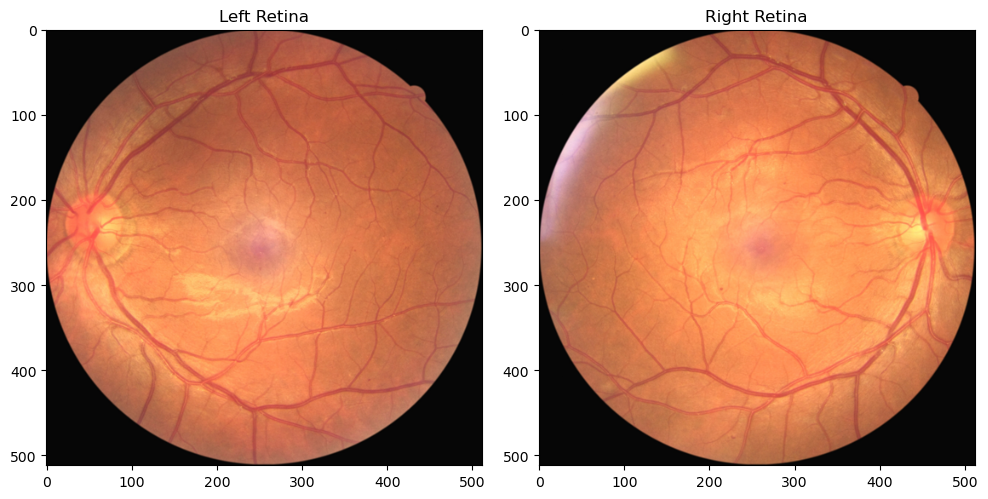

In [132]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img_L)
ax[0].set_title("Left Retina")

ax[1].imshow(img_R)
ax[1].set_title("Right Retina")

plt.tight_layout()
plt.show()



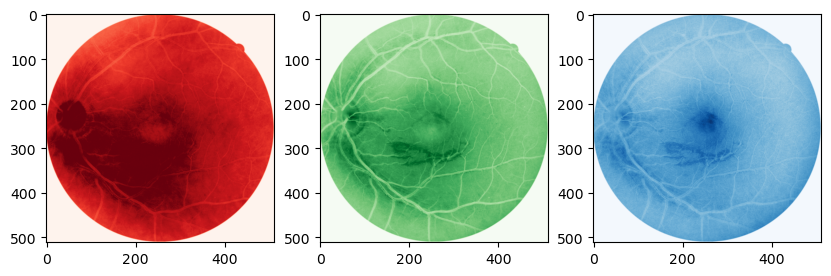

In [133]:
#Displaying 3 color channels sepretly
fig, ax = plt.subplots(1, 3, figsize=(10,10))
ax[0].imshow(img_L[:,:, 0], cmap="Reds")
ax[1].imshow(img_L[:,:, 1], cmap="Greens")
ax[2].imshow(img_L[:,:, 2], cmap="Blues")


plt.show()

In [134]:
raw_data = pd.DataFrame(metadata).T
raw_data.head()

,gender,thickness,label,group,True_age,age,right_eye,left_eye
2491006,0,0.8,0,1,63,0.684932,2491006_R.png,2491006_L.png
3730004,1,1.2,1,1,61,0.657534,3730004_R.png,3730004_L.png
3730006,1,1.2,1,1,64,0.69863,3730006_R.png,3730006_L.png
4738005,0,0.7,0,1,53,0.547945,4738005_R.png,4738005_L.png
6528003,0,1.2,1,1,66,0.726027,6528003_R.png,6528003_L.png


In [135]:
data = raw_data.drop(columns=['right_eye', 'left_eye'])

X_data = data.drop(columns=['thickness'])
y_data = data['thickness']

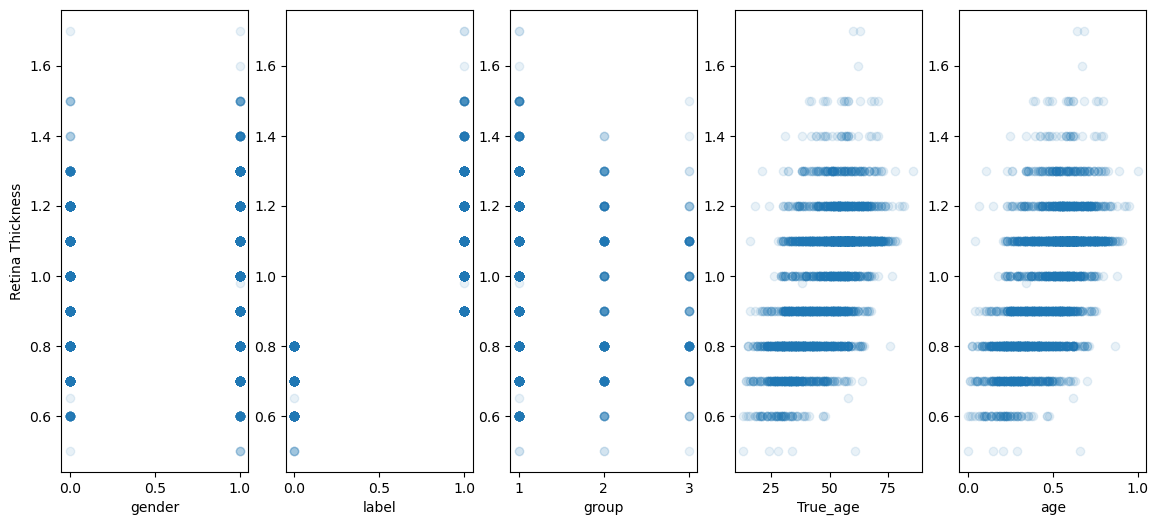

In [136]:
predictors = 5
fig, ax = plt.subplots(1, predictors, figsize=(14, 6))

for idx, columns in enumerate(X_data.columns):
  ax[idx].scatter(X_data[columns], y_data, alpha=0.1)
  ax[idx].set_xlabel(columns)
ax[0].set_ylabel('Retina Thickness')

plt.show()

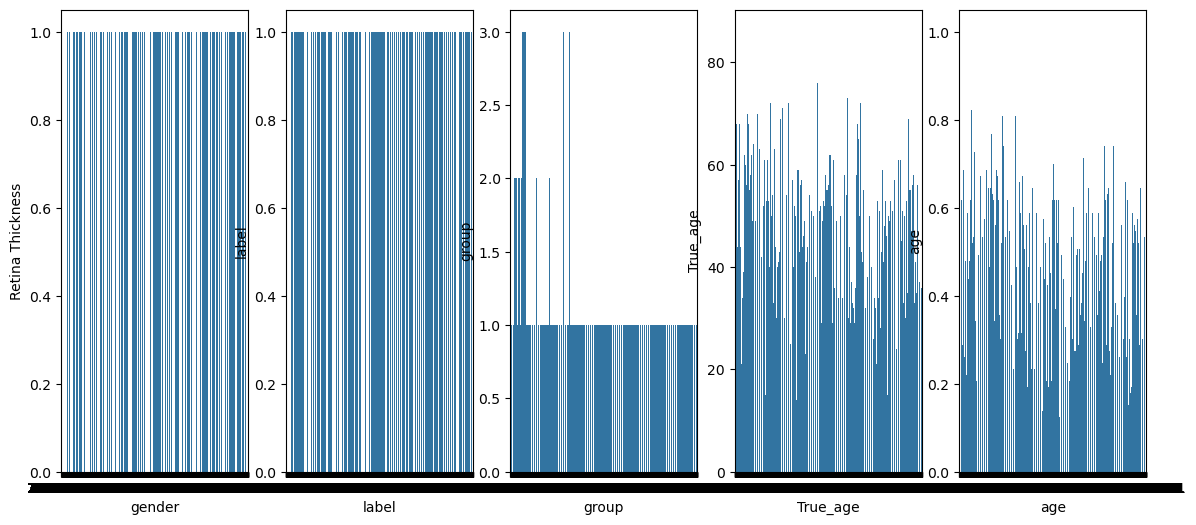

In [137]:
import seaborn as sns

predictors = 5
fig, ax = plt.subplots(1, predictors, figsize=(14, 6))

for idx, columns in enumerate(X_data.columns):
  sns.barplot(X_data[columns], ax=ax[idx])
  ax[idx].set_xlabel(columns)
ax[0].set_ylabel('Retina Thickness')

plt.show()

In [138]:
data.shape

(2903, 6)

In [139]:
import pandas as pd

# Fix orientation if needed
if "label" not in metadata.columns and "label" in metadata.index:
    metadata = metadata.T

# If still missing, reload correctly from file
if "label" not in metadata.columns:
    metadata = pd.read_json(
        "/Users/taliaalmarzouki/Documents/Github /Fundus_CIMT_2903_Dataset/data_info.json",
        orient="index"
    )

print("label in columns?", "label" in metadata.columns)
print("columns:", metadata.columns.tolist()[:10])



label in columns? True
columns: ['gender', 'thickness', 'label', 'group', 'True_age', 'age', 'right_eye', 'left_eye']


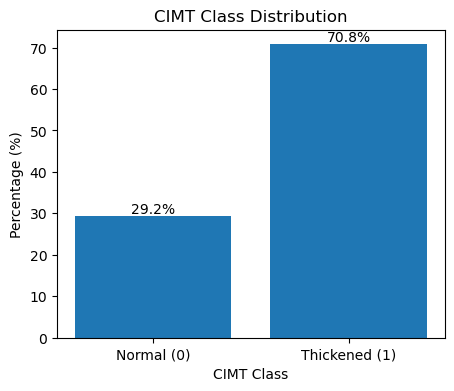

In [ ]:
import matplotlib.pyplot as plt

# Calculate class counts and percentages
class_counts = metadata['label'].value_counts().sort_index()
class_percentages = class_counts / class_counts.sum() * 100

# Define class labels
labels = ['Normal (0)', 'Thickened (1)']

plt.figure(figsize=(5, 4))
bars = plt.bar(labels, class_percentages.values)

plt.ylabel("Percentage (%)")
plt.xlabel("CIMT Class")
plt.title("CIMT Class Distribution")

# Add percentage text on bars
for bar, pct in zip(bars, class_percentages.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{pct:.1f}%",
        ha='center',
        va='bottom'
    )

plt.show()


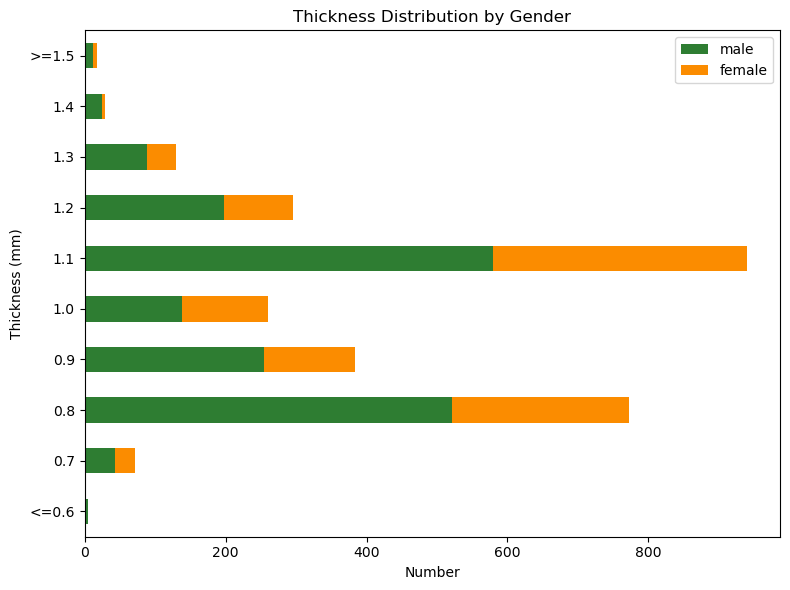

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Fix orientation if needed
if "thickness" not in metadata.columns and "thickness" in metadata.index:
    metadata = metadata.T

# If still missing, reload correctly from file
if not {"thickness", "gender"}.issubset(metadata.columns):
    raise ValueError(f"Need 'thickness' and 'gender'. Columns: {list(metadata.columns)[:20]}")

df = metadata.copy()

# Clean data
df["thickness"] = pd.to_numeric(df["thickness"], errors="coerce")
df["gender"] = pd.to_numeric(df["gender"], errors="coerce")
df = df.dropna(subset=["thickness", "gender"])

# Map gender values: 0=female, 1=male
df["gender"] = df["gender"].astype(int).map({0: "female", 1: "male"})
df = df.dropna(subset=["gender"])

# Thickness bins
bins = [-float("inf"), 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, float("inf")]
labels = ["<=0.6", "0.7", "0.8", "0.9", "1.0", "1.1", "1.2", "1.3", "1.4", ">=1.5"]
df["thickness_bin"] = pd.cut(df["thickness"], bins=bins, labels=labels, include_lowest=True)

# Counts
ct = pd.crosstab(df["thickness_bin"], df["gender"]).reindex(labels, fill_value=0)
for c in ["male", "female"]:
    if c not in ct.columns:
        ct[c] = 0
ct = ct[["male", "female"]]

# Plot
ax = ct.plot(
    kind="barh",
    stacked=True,
    figsize=(8, 6),
    color={"male": "#2E7D32", "female": "#FB8C00"}  # green/orange
)
ax.set_xlabel("Number")
ax.set_ylabel("Thickness (mm)")
ax.set_title("Thickness Distribution by Gender")
ax.legend(title=None)
plt.tight_layout()
plt.show()


Analyzed 5806 images


,brightness_mean,contrast_std,blur_laplacian_var
count,5806.00,5806.00,5806.00
mean,112.68,63.25,89.50
std,17.15,8.55,29.28
min,66.78,38.89,28.83
25%,100.63,57.46,71.90
50%,113.62,63.86,85.56
75%,124.66,69.23,102.31
max,164.42,88.84,269.18


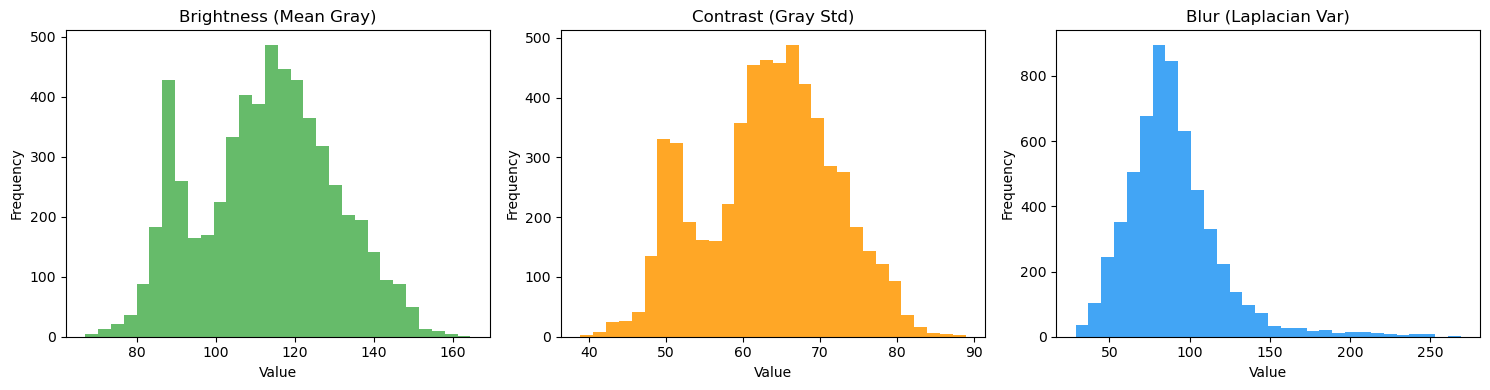

Thresholds -> dark <= 83.40, low contrast <= 48.40, blurry <= 46.35


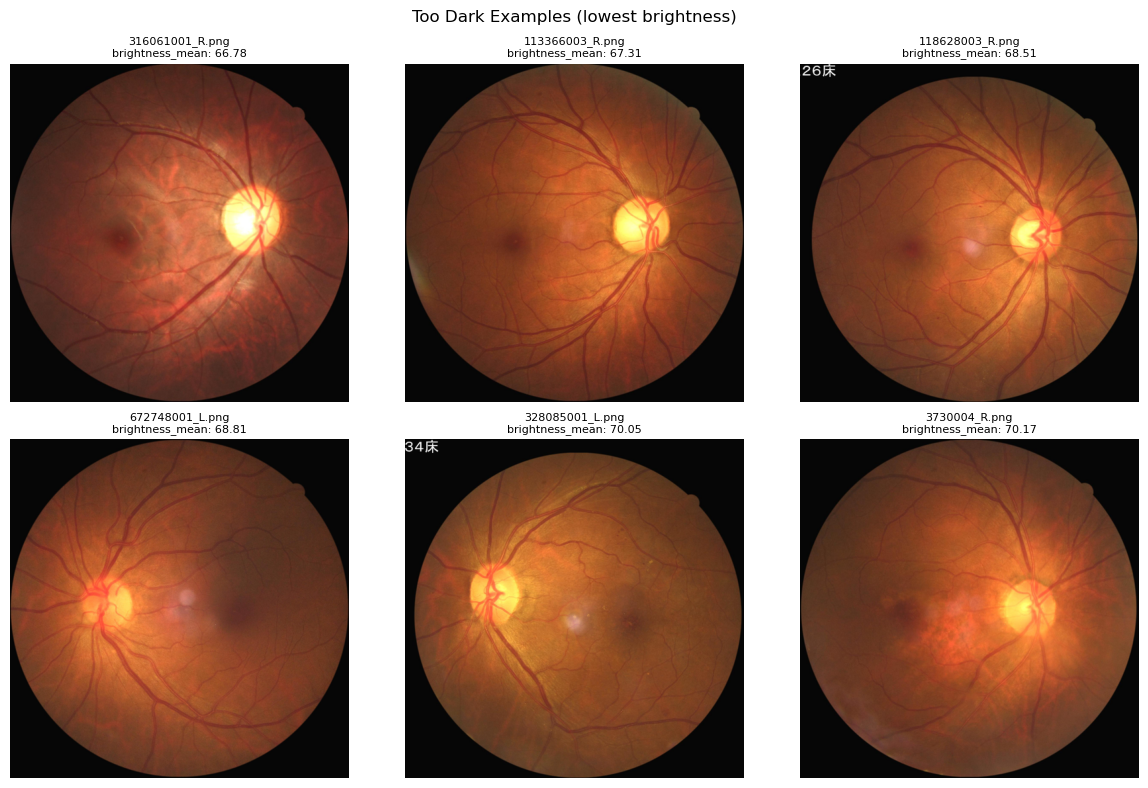

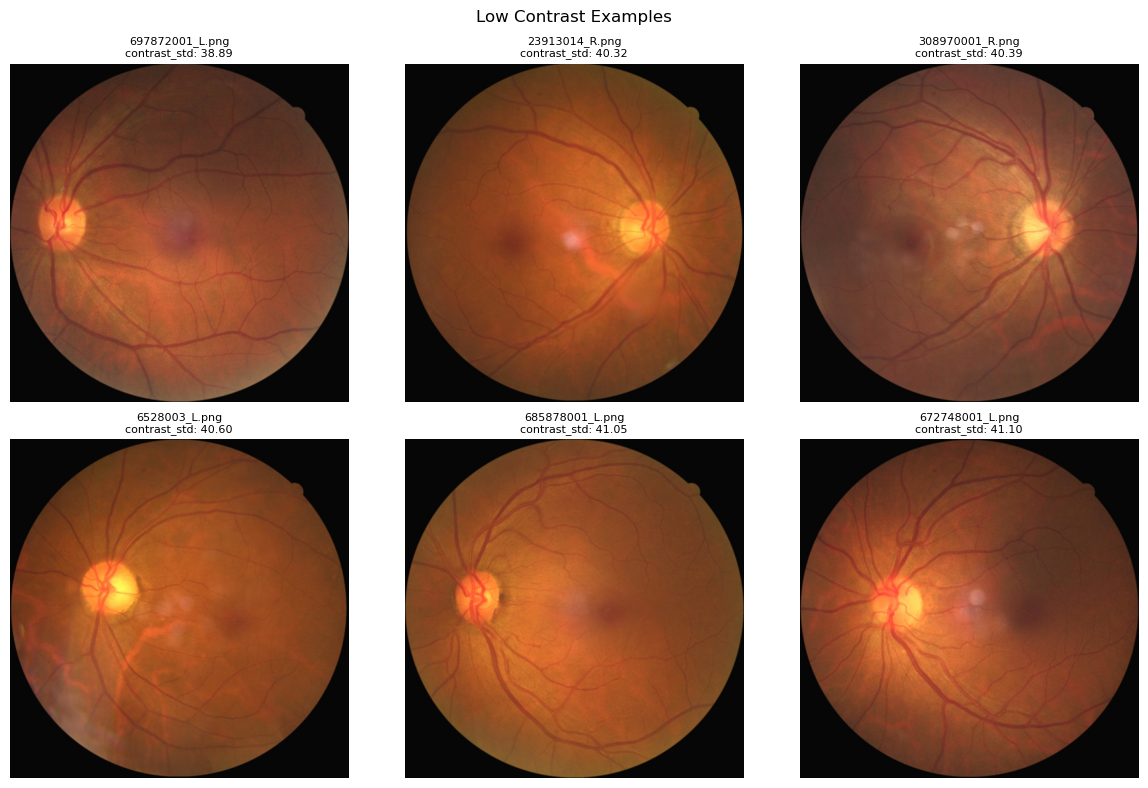

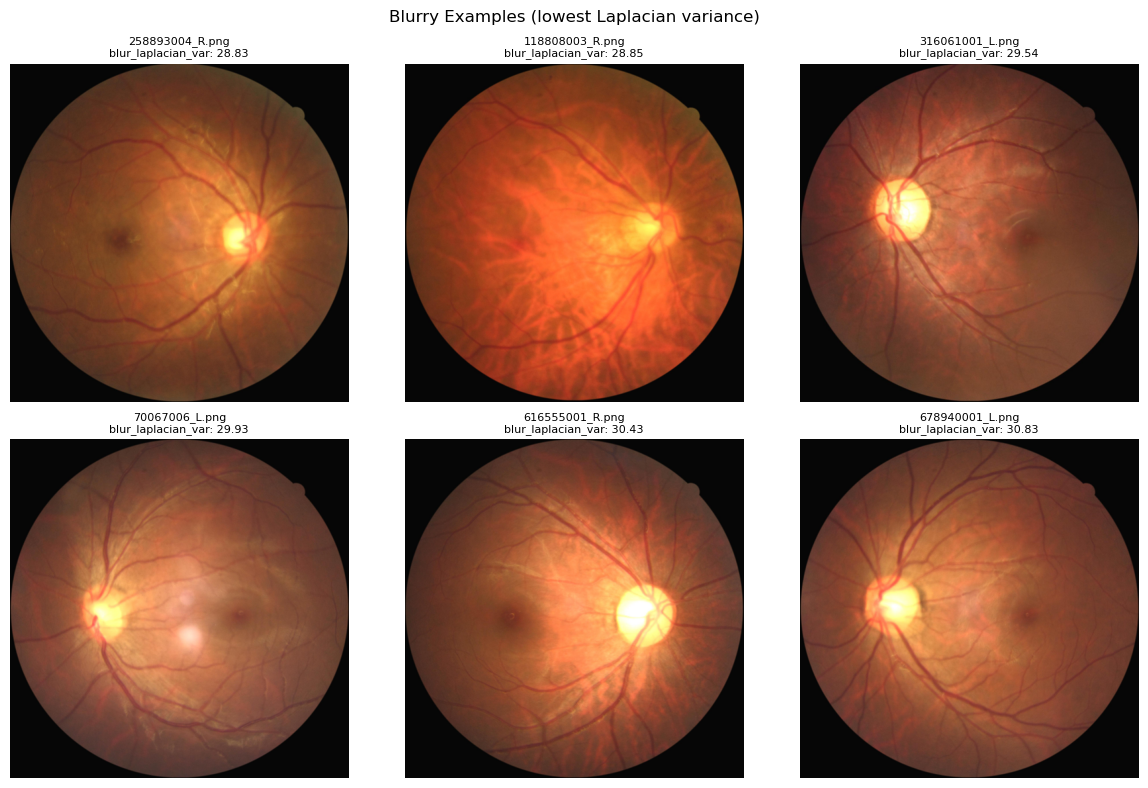

In [144]:
# Image quality analysis: brightness, contrast, blur + outlier examples
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob

# Resolve dataset path from `path` variable if available, otherwise use current working directory
base = Path(path) if 'path' in globals() and path else Path.cwd()
img_paths = sorted(glob(str(base / "Fundus_CIMT_2903_Dataset/images/*.png")))

if len(img_paths) == 0:
    raise ValueError(f"No images found at: {base / 'Fundus_CIMT_2903_Dataset/images/*.png'}")

rows = []
for p in img_paths:
    img = cv2.imread(p)
    if img is None:
        continue
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    rows.append({
        "file": Path(p).name,
        "brightness_mean": float(gray.mean()),                   
        "contrast_std": float(gray.std()),                        
    
        "blur_laplacian_var": float(cv2.Laplacian(gray, cv2.CV_64F).var())  
    })

quality_df = pd.DataFrame(rows)
print(f"Analyzed {len(quality_df)} images")
display(quality_df[["brightness_mean", "contrast_std", "blur_laplacian_var"]].describe().round(2))

# Histograms
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
quality_df["brightness_mean"].plot(kind="hist", bins=30, ax=axes[0], color="#66BB6A", title="Brightness (Mean Gray)")
quality_df["contrast_std"].plot(kind="hist", bins=30, ax=axes[1], color="#FFA726", title="Contrast (Gray Std)")
quality_df["blur_laplacian_var"].plot(kind="hist", bins=30, ax=axes[2], color="#42A5F5", title="Blur (Laplacian Var)")
for a in axes:
    a.set_xlabel("Value")
plt.tight_layout()
plt.show()

# Outlier thresholds (bottom 3%)
dark_thr = quality_df["brightness_mean"].quantile(0.03)
low_contrast_thr = quality_df["contrast_std"].quantile(0.03)
blurry_thr = quality_df["blur_laplacian_var"].quantile(0.03)

out_dark = quality_df[quality_df["brightness_mean"] <= dark_thr].nsmallest(6, "brightness_mean")
out_low_contrast = quality_df[quality_df["contrast_std"] <= low_contrast_thr].nsmallest(6, "contrast_std")
out_blurry = quality_df[quality_df["blur_laplacian_var"] <= blurry_thr].nsmallest(6, "blur_laplacian_var")

print(f"Thresholds -> dark <= {dark_thr:.2f}, low contrast <= {low_contrast_thr:.2f}, blurry <= {blurry_thr:.2f}")

def show_examples(df_subset, metric_col, title):
    if df_subset.empty:
        print(f"No examples for {title}")
        return
    fig, axs = plt.subplots(2, 3, figsize=(12, 8))
    axs = axs.ravel()
    for i, (_, row) in enumerate(df_subset.head(6).iterrows()):
        img = cv2.imread(str(base / "Fundus_CIMT_2903_Dataset/images" / row["file"]))
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axs[i].imshow(img_rgb)
        axs[i].set_title(f"{row['file']}\n{metric_col}: {row[metric_col]:.2f}", fontsize=8)
        axs[i].axis("off")
    for j in range(i + 1, 6):
        axs[j].axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_examples(out_dark, "brightness_mean", "Too Dark Examples (lowest brightness)")
show_examples(out_low_contrast, "contrast_std", "Low Contrast Examples")
show_examples(out_blurry, "blur_laplacian_var", "Blurry Examples (lowest Laplacian variance)")
